In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [2]:
weight = 0.5
bias = 0.3

x = torch.arange(0, 1, step=0.02).unsqueeze(1)
y = x * weight + bias
y

tensor([[0.3000],
        [0.3100],
        [0.3200],
        [0.3300],
        [0.3400],
        [0.3500],
        [0.3600],
        [0.3700],
        [0.3800],
        [0.3900],
        [0.4000],
        [0.4100],
        [0.4200],
        [0.4300],
        [0.4400],
        [0.4500],
        [0.4600],
        [0.4700],
        [0.4800],
        [0.4900],
        [0.5000],
        [0.5100],
        [0.5200],
        [0.5300],
        [0.5400],
        [0.5500],
        [0.5600],
        [0.5700],
        [0.5800],
        [0.5900],
        [0.6000],
        [0.6100],
        [0.6200],
        [0.6300],
        [0.6400],
        [0.6500],
        [0.6600],
        [0.6700],
        [0.6800],
        [0.6900],
        [0.7000],
        [0.7100],
        [0.7200],
        [0.7300],
        [0.7400],
        [0.7500],
        [0.7600],
        [0.7700],
        [0.7800],
        [0.7900]])

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [4]:
split = 40

x_train, x_test = x[:split].to(device=device), x[split:].to(device=device)
y_train, y_test = y[:split].to(device = device), y[split:].to(device = device)
x_test.size()

torch.Size([10, 1])

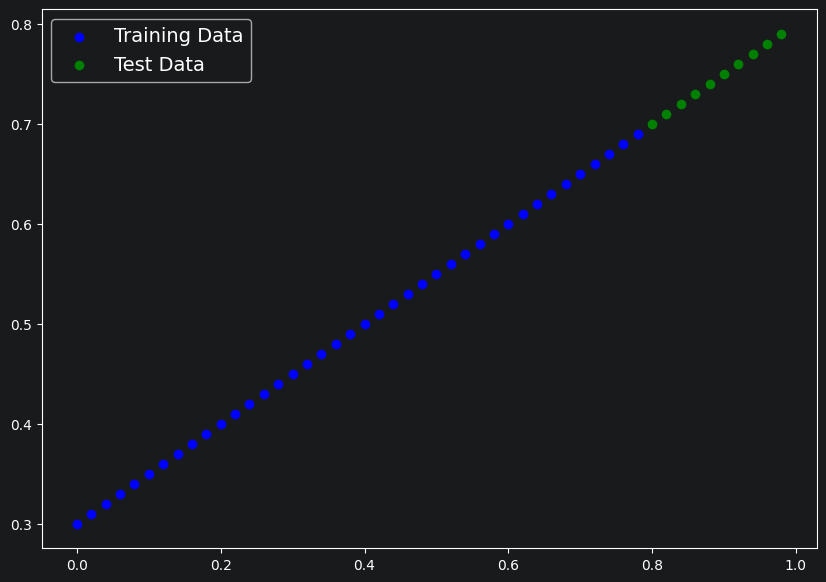

In [5]:
def plot_preds(training_data = x_train.cpu(),
               training_label = y_train.cpu(),
               test_data = x_test.cpu(),
               test_label = y_test.cpu(),
               predictions = None
               ):
    plt.figure(figsize=(10,7))

    plt.scatter(training_data, training_label, color = "b", label = "Training Data")

    plt.scatter(test_data, test_label, color = "g", label = "Test Data")

    if predictions is not None:
        plt.scatter(test_data, predictions.cpu(), color = "r", label = "Predictions")

    plt.legend(prop={"size":14})

plot_preds()

In [6]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer = nn.Linear(in_features = 1,
                                      out_features = 1)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        y = self.linear_layer(x)
        return y

In [7]:
torch.manual_seed(67)

model = LinearRegressionModel()

model.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.4759]])),
             ('linear_layer.bias', tensor([-0.2709]))])

In [8]:
model.to(device=device)

LinearRegressionModel(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)

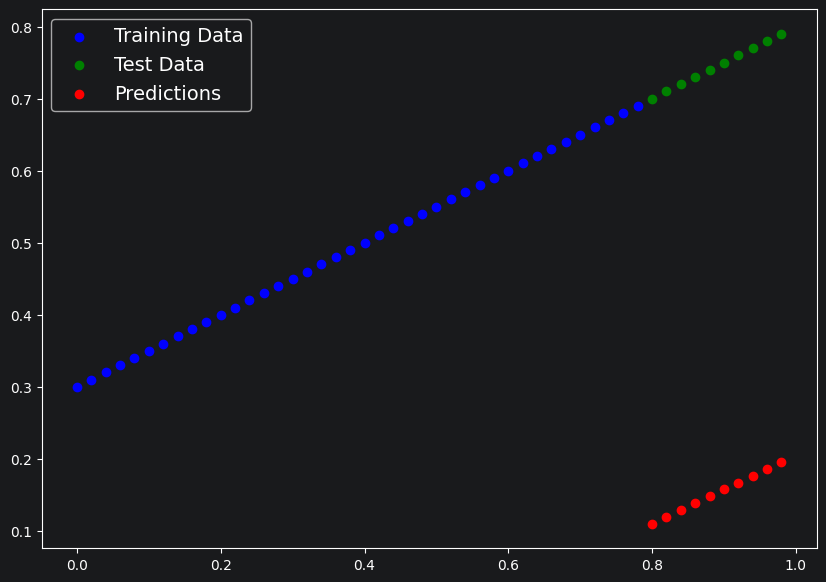

In [9]:
# Pre-test
with torch.inference_mode():
    y_pred = model(x_test)

plot_preds(predictions=y_pred)



In [10]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params = model.parameters(),
                            lr = 0.01)


In [11]:
epoch_count = []
loss_list = []
test_loss_list = []

epochs = 200

for epoch in range(epochs):

    model.train()
    y_pred = model.forward(x_train)
    loss = loss_fn(y_pred, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.inference_mode():
        test_pred = model(x_test)
        test_loss = loss_fn(test_pred, y_test)


    if epoch % 10 == 0:
        epoch_count.append(epoch)
        loss_list.append(loss)
        test_loss_list.append(test_loss)
        print(f"Epoch : {epoch} ! Loss : {loss} ! Test Loss : {test_loss}")



Epoch : 0 ! Loss : 0.5802856683731079 ! Test Loss : 0.5788499116897583
Epoch : 10 ! Loss : 0.46507567167282104 ! Test Loss : 0.4441399574279785
Epoch : 20 ! Loss : 0.34986573457717896 ! Test Loss : 0.30943000316619873
Epoch : 30 ! Loss : 0.23465576767921448 ! Test Loss : 0.17472012341022491
Epoch : 40 ! Loss : 0.11944580078125 ! Test Loss : 0.040010154247283936
Epoch : 50 ! Loss : 0.036480121314525604 ! Test Loss : 0.05917181447148323
Epoch : 60 ! Loss : 0.03025224804878235 ! Test Loss : 0.06769652664661407
Epoch : 70 ! Loss : 0.02675815299153328 ! Test Loss : 0.06148475408554077
Epoch : 80 ! Loss : 0.02332889661192894 ! Test Loss : 0.0538991279900074
Epoch : 90 ! Loss : 0.019893329590559006 ! Test Loss : 0.04562658071517944
Epoch : 100 ! Loss : 0.016455408185720444 ! Test Loss : 0.03804092854261398
Epoch : 110 ! Loss : 0.013026970438659191 ! Test Loss : 0.029768358916044235
Epoch : 120 ! Loss : 0.009589712135493755 ! Test Loss : 0.021495867520570755
Epoch : 130 ! Loss : 0.006153475493

In [12]:
model.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.5087]])),
             ('linear_layer.bias', tensor([0.3006]))])

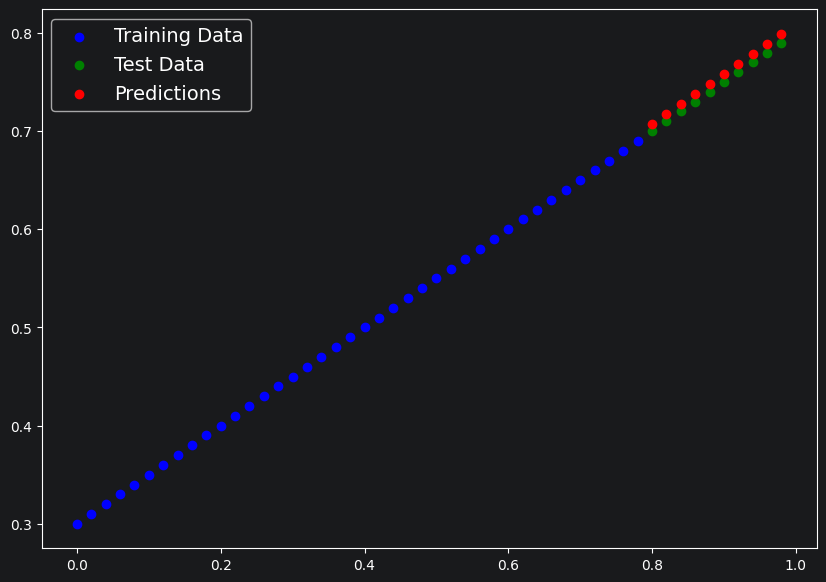

In [13]:
plot_preds(predictions=test_pred.detach())

/var/folders/f8/wk88jm5s3nd2mzv_n2lztngh0000gp/T/ipykernel_2587/3212795682.py:2: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:839.)
  plt.plot(epoch_count, np.array(torch.tensor(loss_list).numpy()), label = "Train Loss")


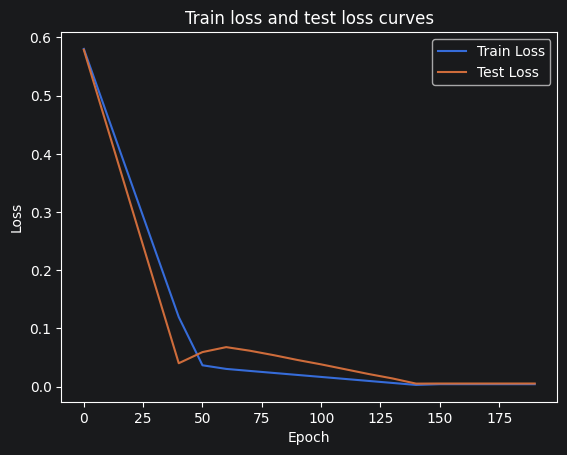

In [14]:
import numpy as np
plt.plot(epoch_count, np.array(torch.tensor(loss_list).numpy()), label = "Train Loss")
plt.plot(epoch_count, np.array(torch.tensor(test_loss_list).numpy()), label = "Test Loss")
plt.title("Train loss and test loss curves")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

In [15]:
from pathlib import Path
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok= True)

MODEL_NAME = "basic_model"

MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

torch.save(model.state_dict(), MODEL_SAVE_PATH)

In [16]:
loaded_model = LinearRegressionModel()
loaded_model.load_state_dict(torch.load(MODEL_SAVE_PATH, weights_only=True))
loaded_model.to(device=device)

LinearRegressionModel(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)

In [17]:
loaded_model.state_dict()


OrderedDict([('linear_layer.weight', tensor([[0.5087]])),
             ('linear_layer.bias', tensor([0.3006]))])